# $\phi$ \ $\chi$ spectra
Comparing observed spectra of acoustic phase, $\phi$ and log-amplitude, $\chi$ with modelled spectra given Garrett-Munk internal waves spectra (calculated with WFT).

In [1]:
import os
import pickle

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from dotenv import find_dotenv, load_dotenv
from scipy import signal

from nescafe23_fluctuations import tools

_ = load_dotenv(find_dotenv())

%config InlineBackend.figure_format = 'retina'
%load_ext autoreload
%autoreload 2

/Users/john/Code/NESCAFE/nescafe_23_fluctuations/src/nescafe23_fluctuations/tools.py:1053: SyntaxWarning: invalid escape sequence '\p'
  """


## open observations

In [2]:
fn = f"{os.environ['NESCAFE23_DATADIR']}dataproducts/wavefront_values.pkl"

with open(fn, "rb") as f:
    wavefront_values = pickle.load(f)

In [3]:
ray_ids = ["+7", "-7", "-6", "+6"]

F_chi_data = {}
F_phi_data = {}
F_phi_data_out = {}

F_chi_lm = {}
F_chi_ls = {}
F_phi_lm = {}
F_phi_ls = {}
F_phi_lm_out = {}
F_phi_ls_out = {}


for ray_id in ray_ids:
    # extract amplitude, intensity, and phase from wavefront values
    amp = np.abs(wavefront_values[ray_id])
    lamp = np.log(amp)
    I = amp**2
    phase = np.unwrap(np.angle(wavefront_values[ray_id]), axis=1)

    phase_out = phase.copy()
    phase_out[np.s_[:, np.r_[4:6, 20]]] = np.nan
    phase_nm = phase_out - np.nanmean(phase_out, axis=1)[:, None]
    phase_nm[np.isnan(phase_nm)] = 0

    m_data, F_chi_data[ray_id] = signal.periodogram(lamp, fs=1 / 9, axis=1)

    # m_data [1/m]
    # F_chi_data [rad m]
    _, F_phi_data[ray_id] = signal.periodogram(phase, fs=1 / 9, axis=1)
    _, F_phi_data_out[ray_id] = signal.periodogram(phase_nm, fs=1 / 9, axis=1)

    # remove DC comp
    m_data = m_data[1:]
    F_chi_data[ray_id] = F_chi_data[ray_id][:, 1:]
    F_phi_data[ray_id] = F_phi_data[ray_id][:, 1:]
    F_phi_data_out[ray_id] = F_phi_data_out[ray_id][:, 1:]

    # Take mean and standard deviation in log space
    F_chi_lm[ray_id] = 10 ** np.mean(np.log10(F_chi_data[ray_id]), axis=0)
    F_chi_ls[ray_id] = 10 ** np.std(np.log10(F_chi_data[ray_id]), axis=0)

    F_phi_lm[ray_id] = 10 ** np.mean(np.log10(F_phi_data[ray_id]), axis=0)
    F_phi_ls[ray_id] = 10 ** np.std(np.log10(F_phi_data[ray_id]), axis=0)

    F_phi_lm_out[ray_id] = 10 ** np.mean(np.log10(F_phi_data_out[ray_id]), axis=0)
    F_phi_ls_out[ray_id] = 10 ** np.std(np.log10(F_phi_data_out[ray_id]), axis=0)

### Demonstrate outlier removal

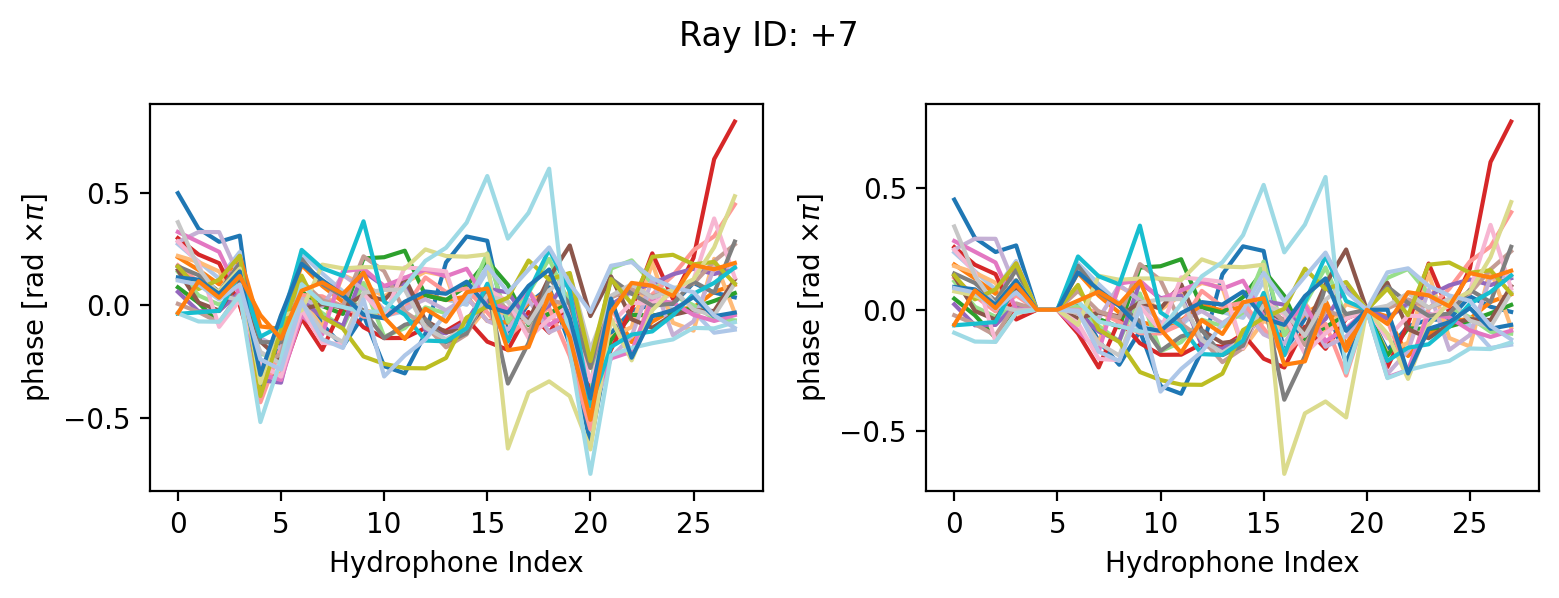

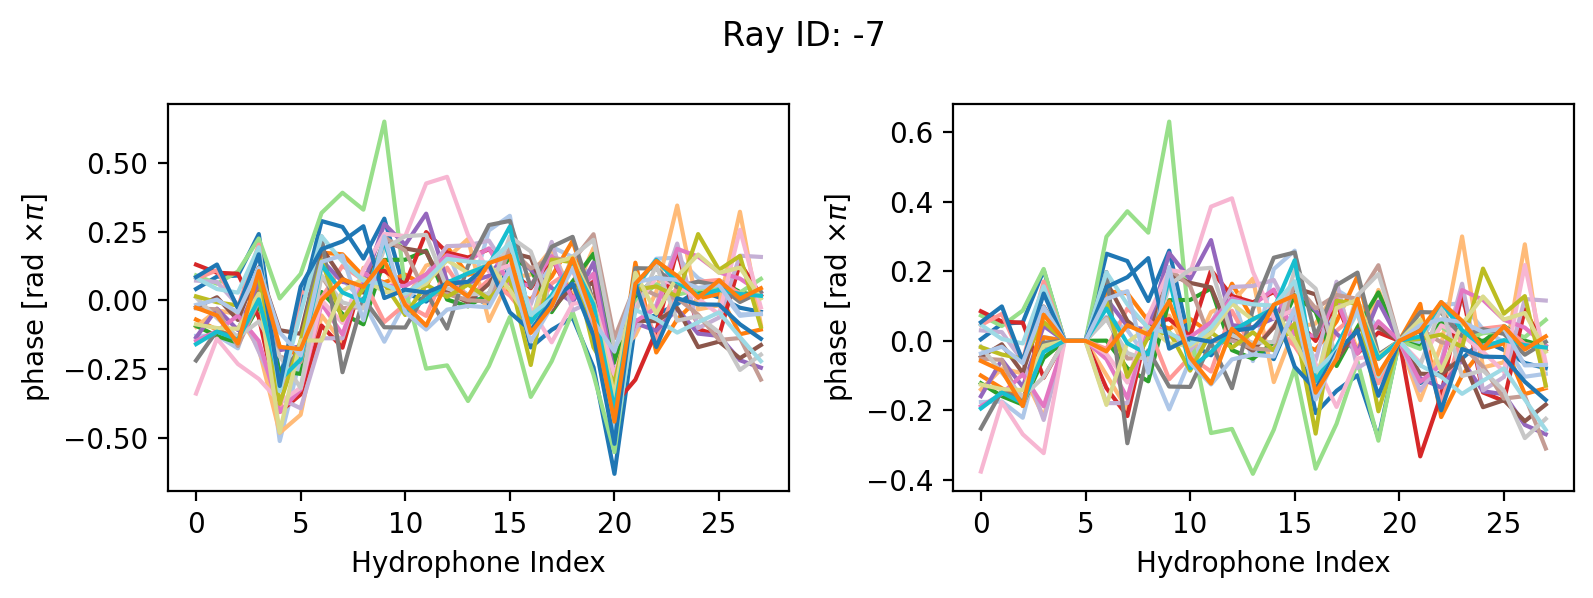

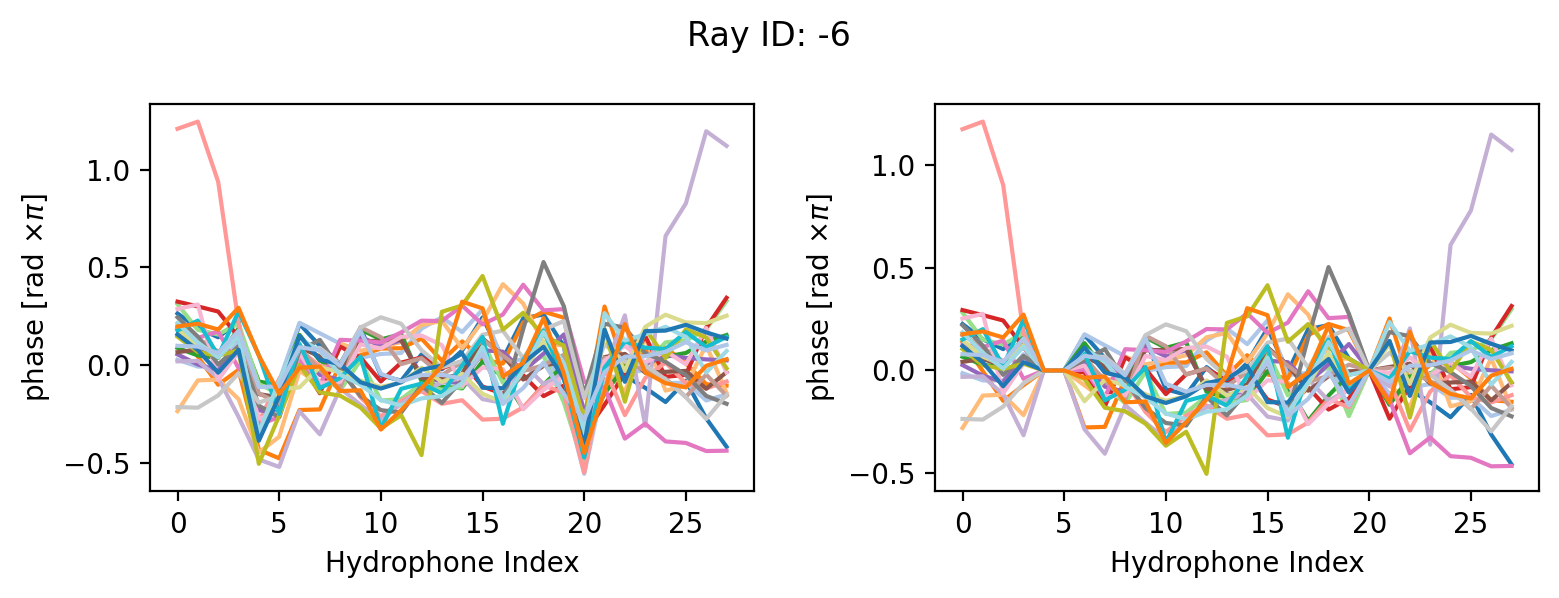

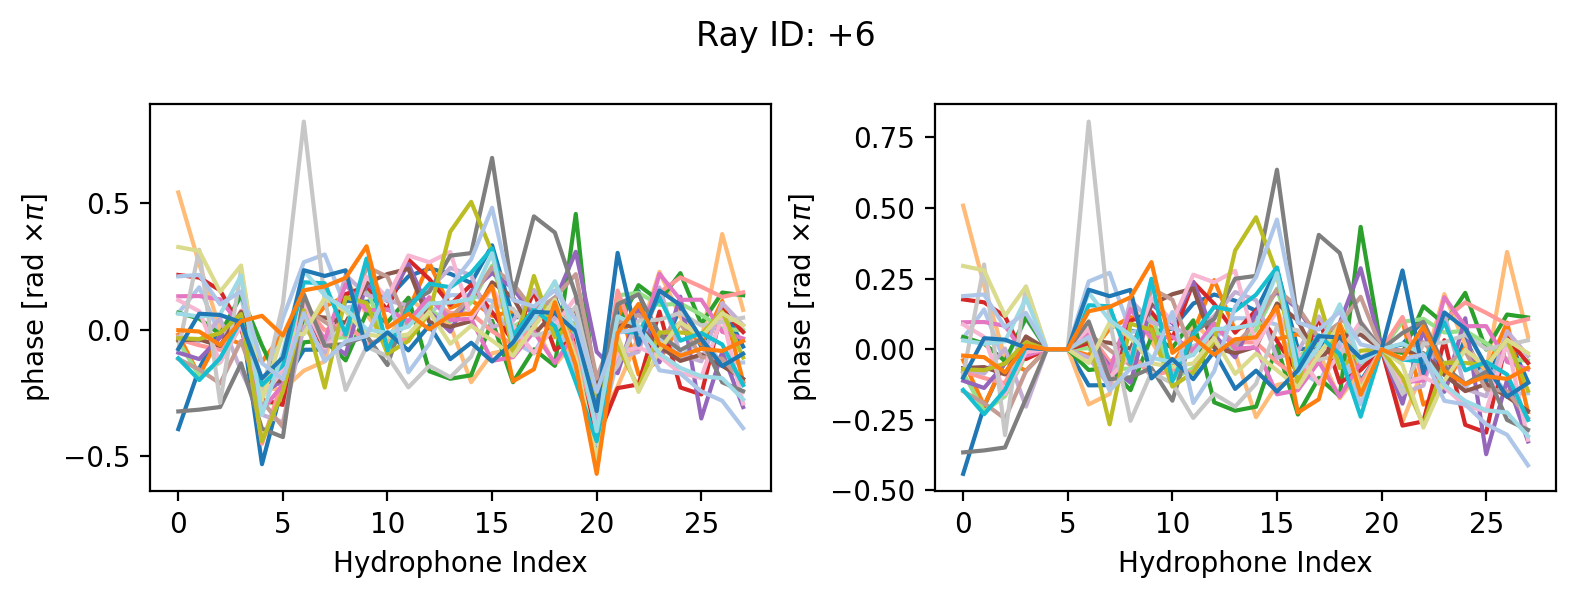

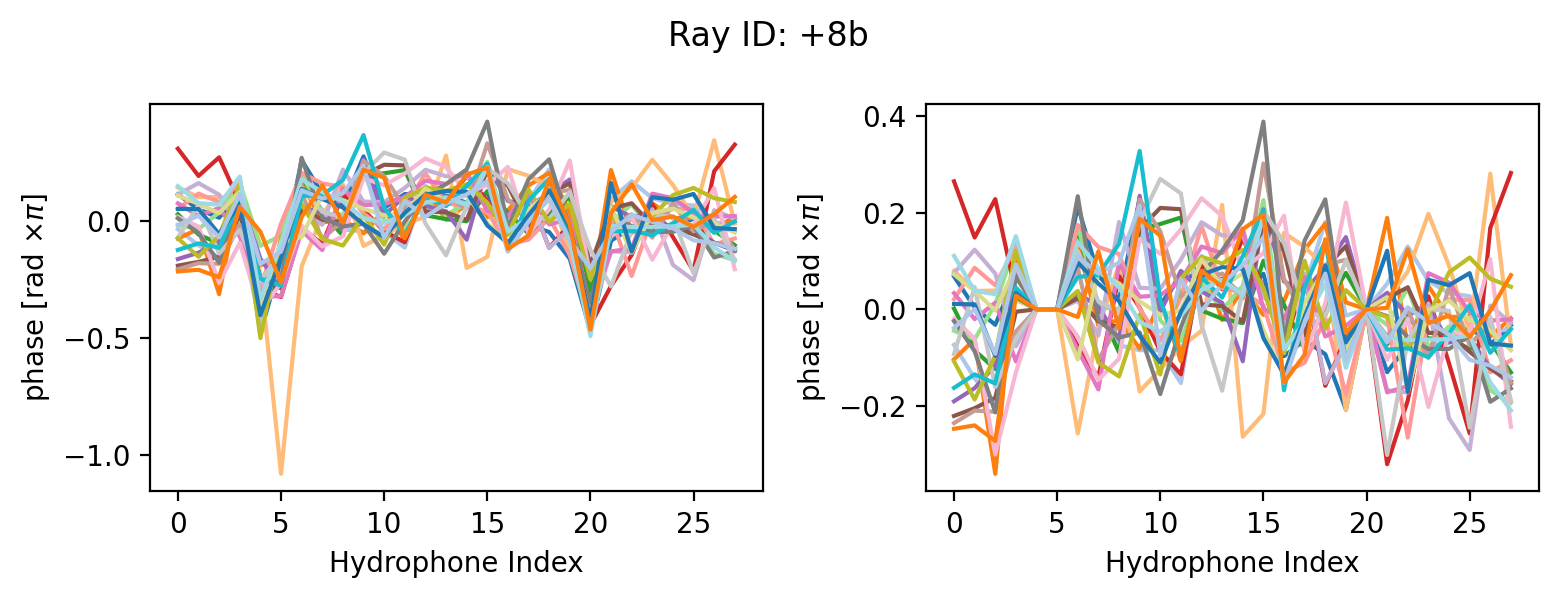

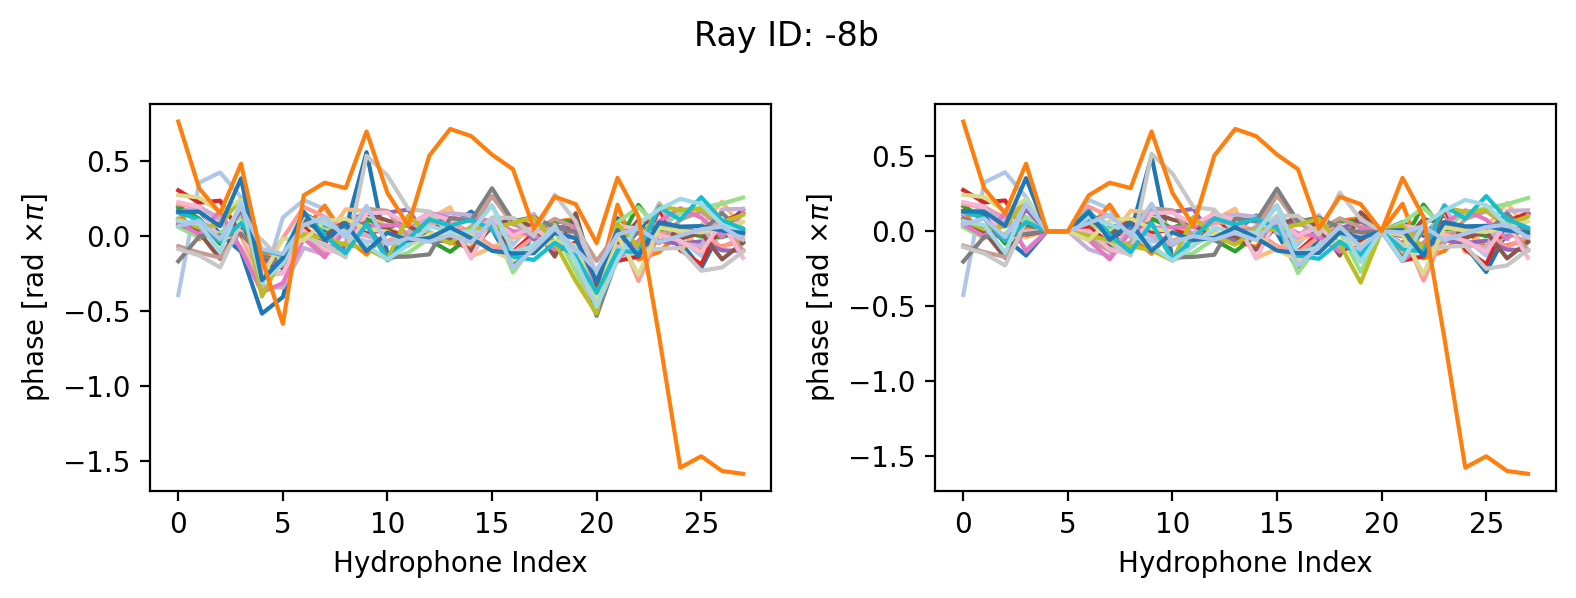

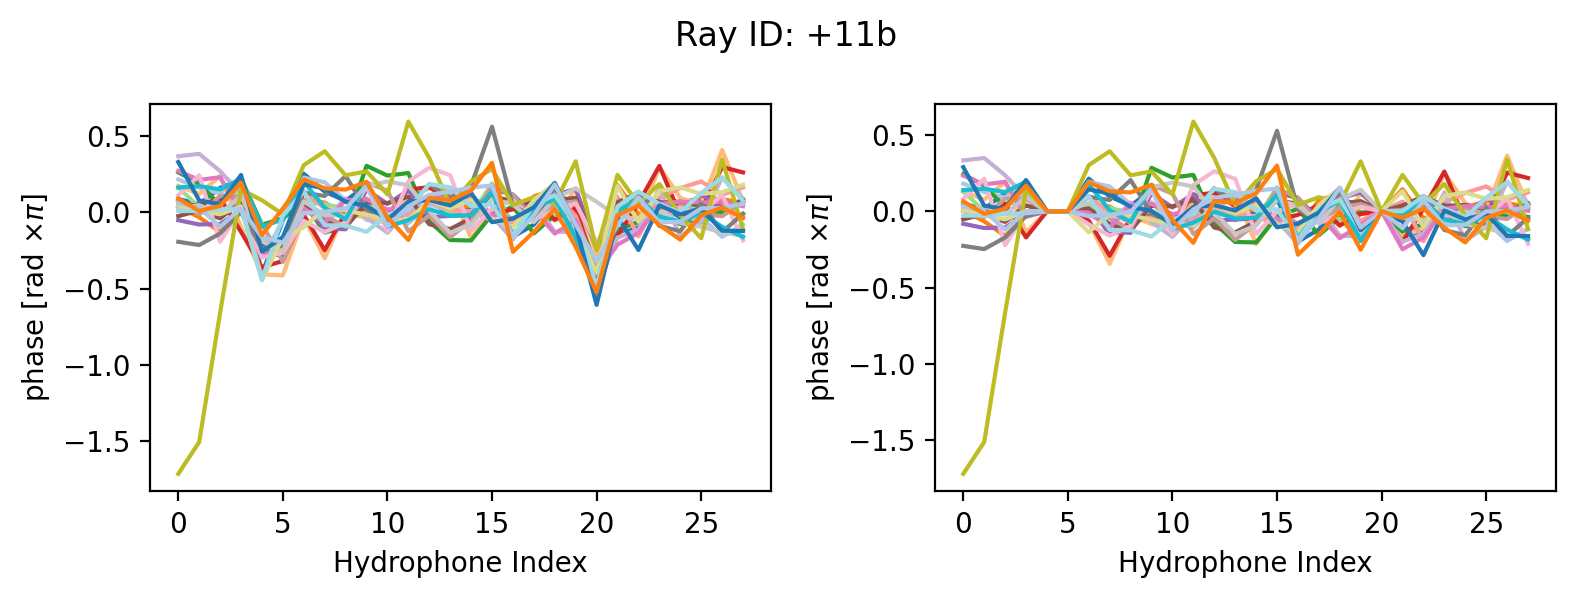

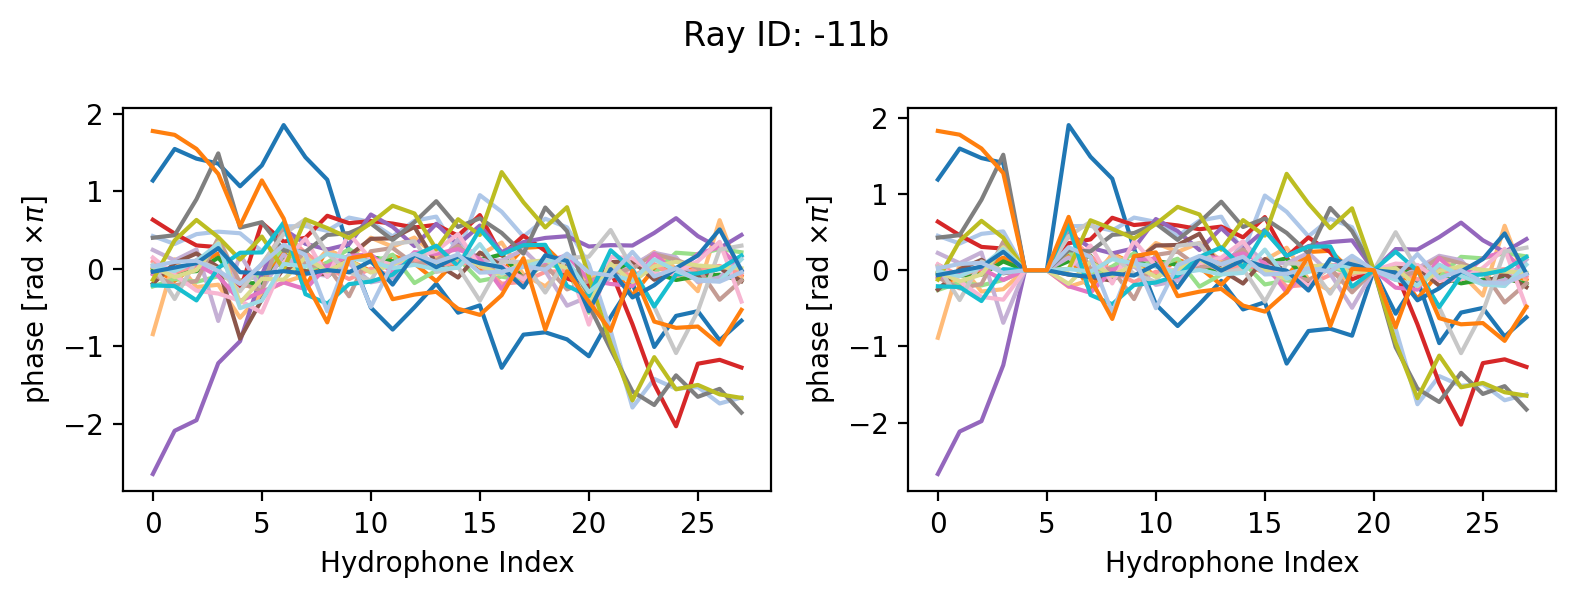

In [42]:
ray_ids = ["+7", "-7", "-6", "+6", "+8b", "-8b", "+11b", "-11b"]

for ray_id in ray_ids:
    phase = np.unwrap(np.angle(wavefront_values[ray_id]), axis=1)

    phase_out = phase.copy()
    phase_out[np.s_[:, np.r_[4:6, 20]]] = np.nan
    phase_nm = phase_out - np.nanmean(phase_out, axis=1)[:, None]
    phase_nm[np.isnan(phase_nm)] = 0

    fig = plt.figure(figsize=(8, 3))
    fig.suptitle(f"Ray ID: {ray_id}")

    plt.subplot(1, 2, 1)
    _ = plt.plot((phase.T - np.mean(phase, axis=1)[None, :]) / np.pi)
    plt.xlabel("Hydrophone Index")
    plt.ylabel("phase [rad $\\times \\pi$]")

    plt.subplot(1, 2, 2)
    _ = plt.plot(phase_nm.T / np.pi)

    plt.xlabel("Hydrophone Index")
    plt.ylabel("phase [rad $\\times \\pi$]")

    plt.tight_layout()

    fig.savefig(f"../../figures/auxiliary/phase_outlier_removal/{ray_id}.png", dpi=300)

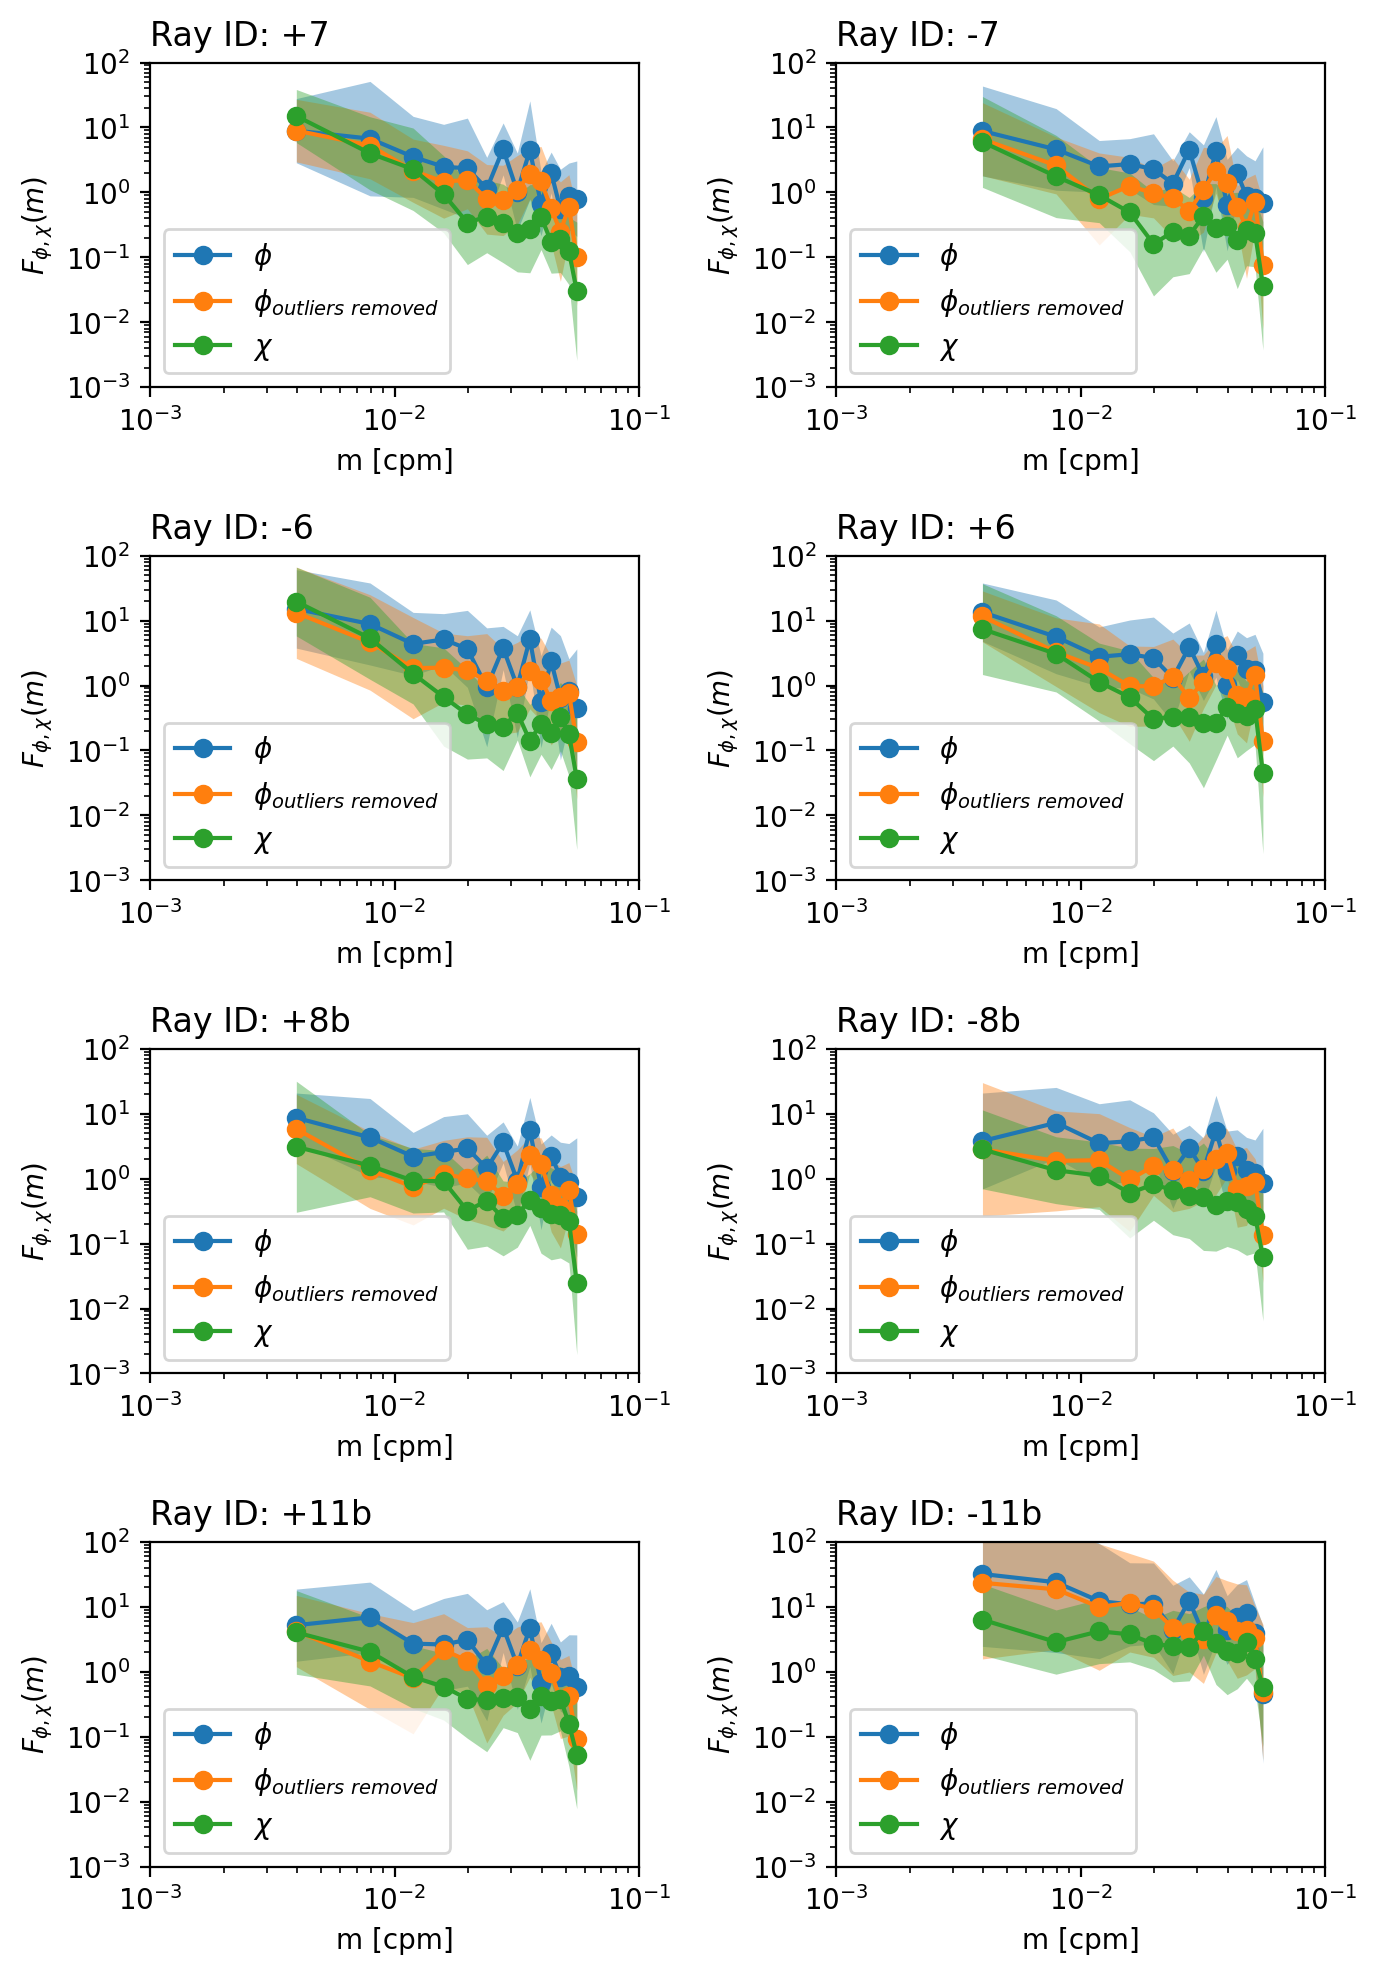

In [48]:
sns.set_palette("tab20")

fig, axes = plt.subplots(4, 2, figsize=(7, 10))
axes = axes.flatten()

for k, ray_id in enumerate(ray_ids):
    plt.sca(axes[k])
    plt.plot(m_data, F_phi_lm[ray_id], c="C0", marker="o", label="$\\phi$")
    plt.fill_between(
        m_data,
        F_phi_lm[ray_id] * F_phi_ls[ray_id],
        F_phi_lm[ray_id] / F_phi_ls[ray_id],
        alpha=0.4,
        color="C0",
        lw=0,
    )

    plt.plot(
        m_data,
        F_phi_lm_out[ray_id],
        c="C2",
        marker="o",
        label="$\\phi_{outliers \\ removed}$",
    )
    plt.fill_between(
        m_data,
        F_phi_lm_out[ray_id] * F_phi_ls_out[ray_id],
        F_phi_lm_out[ray_id] / F_phi_ls_out[ray_id],
        alpha=0.4,
        color="C2",
        lw=0,
    )

    plt.plot(m_data, F_chi_lm[ray_id], c="C4", marker="o", label="$\\chi$")
    plt.fill_between(
        m_data,
        F_chi_lm[ray_id] * F_chi_ls[ray_id],
        F_chi_lm[ray_id] / F_chi_ls[ray_id],
        alpha=0.4,
        color="C4",
        lw=0,
    )

    plt.yscale("log")
    plt.xscale("log")

    plt.xlim([1e-3, 1e-1])
    plt.ylim([1e-3, 1e2])

    plt.title(f"Ray ID: {ray_id}", loc="left")
    plt.legend()
    plt.xlabel("m [cpm]")
    plt.ylabel("$F_{\\phi, \\chi}(m)$")

plt.tight_layout(pad=1)

# fig.savefig('../../figures/auxiliary/phase_outlier_removal/spectra_comparison.png', dpi=300)

## Compute internal wave spectra (WFT)

In [21]:
zeta0 = 7.3 * np.sqrt(1)

In [22]:
rvs = tools.compute_n23_ray_variables(zeta0=zeta0)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 25/25 [00:03<00:00,  7.02it/s]


In [23]:
m = 2 * np.pi * np.logspace(-5, 0, 500)[None, :]  # [rad / m]

F_phis = {}
F_chis = {}

for ray_id in ["+7", "-7", "+6", "-6"]:
    F_phis[ray_id], F_chis[ray_id] = tools.compute_F_phi_chi(rvs[ray_id], m)

## Plot Spectra

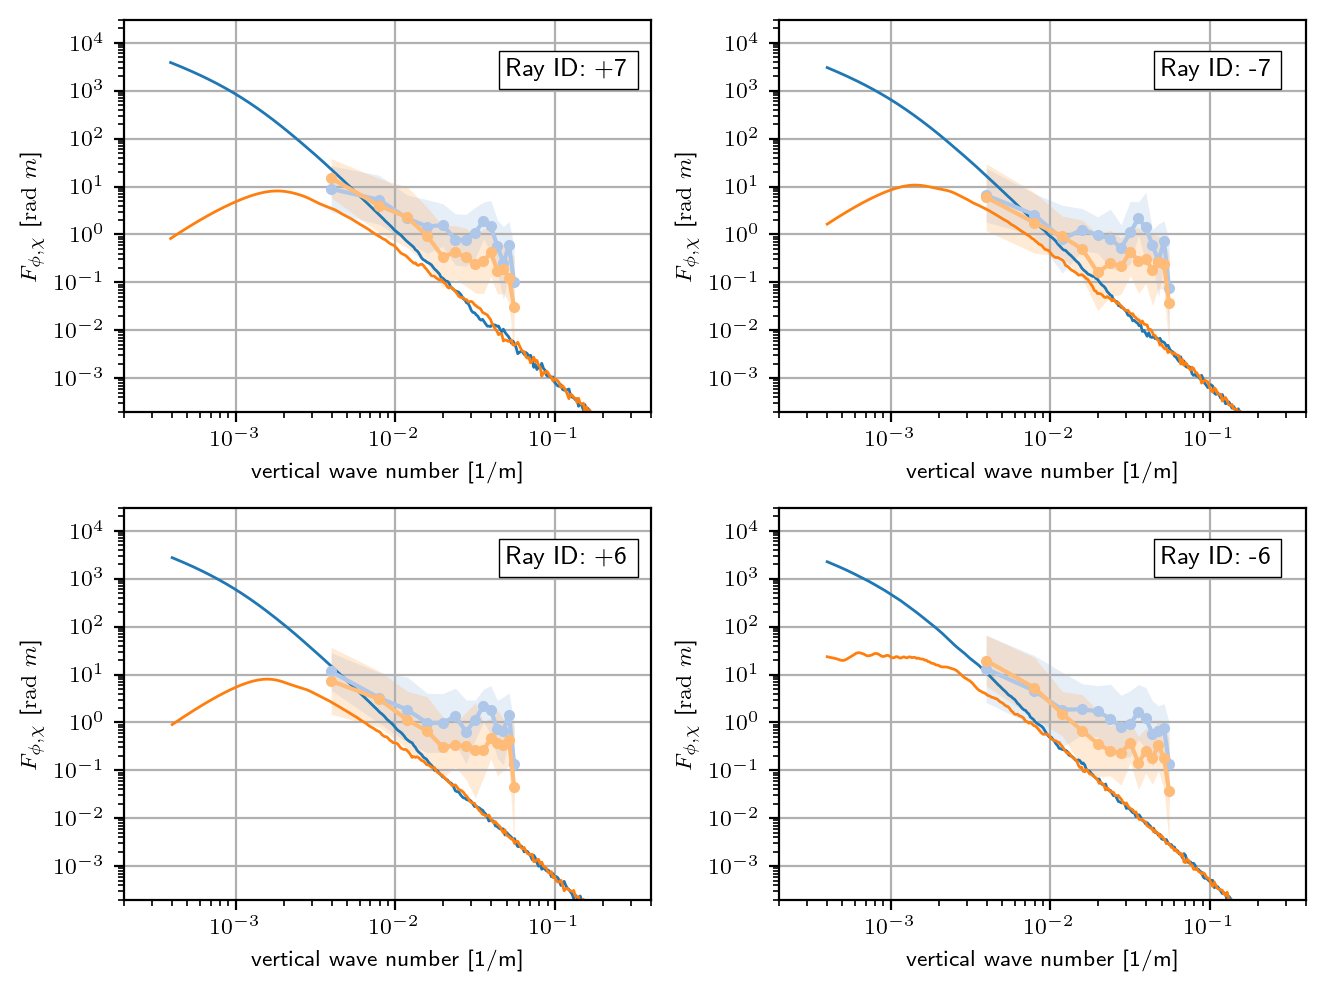

In [24]:
plt.rcParams.update({"font.size": 8})
plt.rcParams["text.usetex"] = True
sns.set_palette("tab20")

fig, axes = plt.subplots(2, 2, figsize=(6.67, 5))
axes = axes.flatten()

for k, ray_id in enumerate(["+7", "-7", "+6", "-6"]):
    plt.sca(axes[k])

    # WFT GMIW F_phi
    plt.plot(m[0] / (2 * np.pi), F_phis[ray_id], c="C0", lw=1)

    # F_phi observed
    plt.plot(m_data, F_phi_lm_out[ray_id], c="C1", marker="o", markersize=3)
    plt.fill_between(
        m_data,
        F_phi_lm_out[ray_id] * F_phi_ls_out[ray_id],
        F_phi_lm_out[ray_id] / F_phi_ls_out[ray_id],
        alpha=0.3,
        color="C1",
        lw=0,
    )

    # WFT GMIW F_chi
    plt.plot(m[0] / (2 * np.pi), F_chis[ray_id], c="C2", lw=1)

    # F_chi observed
    plt.plot(m_data, F_chi_lm[ray_id], c="C3", marker="o", markersize=3)
    plt.fill_between(
        m_data,
        F_chi_lm[ray_id] * F_chi_ls[ray_id],
        F_chi_lm[ray_id] / F_chi_ls[ray_id],
        alpha=0.3,
        color="C3",
        lw=0,
    )

    plt.ylim([2e-4, 3e4])
    plt.xlim([2e-4, 4e-1])

    plt.xlabel("vertical wave number [1/m]")
    plt.ylabel("$F_{\\phi, \\chi}$ [$\\mathrm{rad} \\ m$]")

    plt.yscale("log")
    plt.xscale("log")

    plt.grid()

    plt.text(
        5e-2,
        2e3,
        f"Ray ID: {ray_id}",
        fontsize=9,
        bbox=dict(facecolor="white", edgecolor="k", pad=3, linewidth=0.5),
    )

plt.tight_layout()

# fig.savefig('../../figures/F_phi_chi_ducted.pdf', bbox_inches='tight')

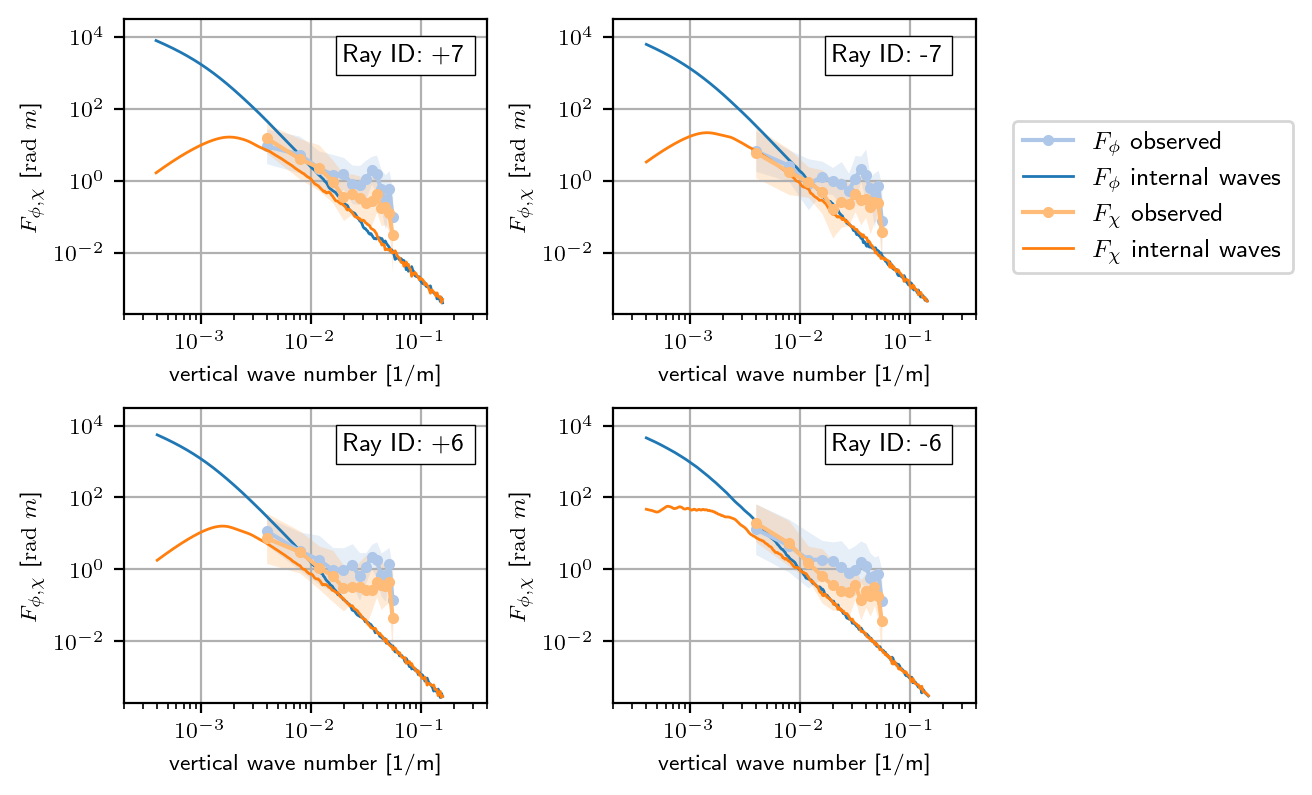

In [44]:
plt.rcParams.update({"font.size": 8})
plt.rcParams["text.usetex"] = True
sns.set_palette("tab20")

fig, axes = plt.subplots(2, 2, figsize=(6.67, 4))
axes = axes.flatten()

for k, ray_id in enumerate(["+7", "-7", "+6", "-6"]):
    plt.sca(axes[k])

    # WFT GMIW F_phi
    (line1,) = plt.plot(
        m[0] / (2 * np.pi),
        F_phis[ray_id],
        c="C0",
        lw=1,
        label="$F_{\\phi}$ internal waves",
    )

    # F_phi observed
    (line2,) = plt.plot(
        m_data,
        F_phi_lm_out[ray_id],
        c="C1",
        marker="o",
        markersize=3,
        label="$F_{\\phi}$ observed",
    )
    plt.fill_between(
        m_data,
        F_phi_lm_out[ray_id] * F_phi_ls_out[ray_id],
        F_phi_lm_out[ray_id] / F_phi_ls_out[ray_id],
        alpha=0.3,
        color="C1",
        lw=0,
    )

    # WFT GMIW F_chi
    (line3,) = plt.plot(
        m[0] / (2 * np.pi),
        F_chis[ray_id],
        c="C2",
        lw=1,
        label="$F_{\\chi}$ internal waves",
    )

    # F_chi observed
    (line4,) = plt.plot(
        m_data,
        F_chi_lm[ray_id],
        c="C3",
        marker="o",
        markersize=3,
        label="$F_{\\chi}$ observed",
    )
    plt.fill_between(
        m_data,
        F_chi_lm[ray_id] * F_chi_ls[ray_id],
        F_chi_lm[ray_id] / F_chi_ls[ray_id],
        alpha=0.3,
        color="C3",
        lw=0,
    )

    plt.ylim([2e-4, 3e4])
    plt.xlim([2e-4, 4e-1])

    plt.xlabel("vertical wave number [1/m]")
    plt.ylabel("$F_{\\phi, \\chi}$ [$\\mathrm{rad} \\ m$]")

    plt.yscale("log")
    plt.xscale("log")

    plt.grid()

    plt.text(
        2e-2,
        2e3,
        f"Ray ID: {ray_id}",
        fontsize=9,
        bbox=dict(facecolor="white", edgecolor="k", pad=3, linewidth=0.5),
    )

# Adjust subplot positioning to make room for legend
plt.tight_layout(pad=1, rect=[0, 0, 0.75, 1])

# Create legend using handles from the last subplot
handles = [line2, line1, line4, line3]
labels = [
    "$F_{\\phi}$ observed",
    "$F_{\\phi}$ internal waves",
    "$F_{\\chi}$ observed",
    "$F_{\\chi}$ internal waves",
]
fig.legend(
    handles,
    labels,
    loc="center right",
    bbox_to_anchor=(0.98, 0.75),
    fontsize=9,
    frameon=True,
)

fig.savefig("../../figures/F_phi_chi_ducted.pdf", bbox_inches="tight")